# Real-Space Self-Energies with `sisl`: a beginner's tutorial


So far, we have done transport calculations where semi-infinite electrodes were attached along a single transport direction (see *(b)*). 
A **real-space self-energy (RSSE)** provides a different type of embedding: it allows a finite region to reproduce the effect of an extended periodic environment around it (see *(c)*). This is particularly important when describing single defects on a material.

![title](./Figures/rsse.jpg)

A real-space self-energy is obtained from a Brillouin-zone-averaged Green function and embeds a finite device into an extended periodic 2D or 3D material. For an STM junction, this lets us model a local tip above an effectively infinite graphene sheet without periodically repeating the tip.

In TBtrans and TranSiesta one is capable of performing real-space transport calculations by using real-space self-energies (see here).
Currently, the real-space self-energy calculation has to be performed in sisl since it is not implemented in TranSiesta.



This tutorial introduces the basic ingredients of quantum transport calculations with **sisl** using real space (surrounding) self energies RSSE. 
The tutorial is divided into four parts:

1. **Real-space self-energies (RSSE) for graphene.** We build a simple graphene tight-binding model and use a real-space self-energy to embed a finite graphene region in an otherwise infinite graphene sheet. We then calculate the DOS and LDOS from the retarded Green function.
2. **Carbon vacancy in graphene**. We employ the real space self energy to study the localized state arising from a carbon vacancy in graphene.
3. **STM wire injecting into graphene.** We attach an explicit Au chain to the graphene device and calculate transmission and injected bond currents.
4. **Vertical graphene–CNT–graphene transport.** We construct a carbon nanotube (CNT) connected between two graphene sheets, reuse the graphene RSSEs as electrodes, and calculate transmission, DOS, and spatially resolved LDOS.

This tutorial was created by Alan Anaya mainly inspired by previous tutorials by Nick Papior

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from tqdm.notebook import tqdm

import sisl as si
import sisl.viz  # enables the .plot() methods on sisl objects

si.__version__

'0.20.0'

All figures share a few default settings, and a few small helpers are used to draw atoms (projected on two Cartesian axes), LDOS maps and bond currents.

In [2]:
# Default figure settings used throughout the tutorial
plt.rcParams.update({
    "figure.figsize": (4, 4),
    "image.cmap": "inferno",     # default colormap, also used by scatter plots
    "scatter.edgecolors": "k",
    "legend.framealpha": 1,
})

AXES = {"x": 0, "y": 1, "z": 2}


def add_colorbar(ax, mappable, label):
    """Attach a colorbar with the same height as `ax`."""
    cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.08)
    return ax.figure.colorbar(mappable, cax=cax, label=label)


def plot_atoms(ax, xyz, axes="xy", **kwargs):
    """Scatter atomic positions projected onto the plane spanned by `axes` (e.g. "xy" or "xz")."""
    a, b = AXES[axes[0]], AXES[axes[1]]
    ax.set_aspect("equal")
    ax.set_xlabel(rf"${axes[0]}$ [$\AA$]")
    ax.set_ylabel(rf"${axes[1]}$ [$\AA$]")
    return ax.scatter(xyz[:, a], xyz[:, b], **kwargs)


def plot_ldos(ax, xyz, ldos, axes="xy", **kwargs):
    """Atoms colored by their LDOS, with a colorbar."""
    sc = plot_atoms(ax, xyz, axes, c=ldos, vmin=0, **kwargs)
    add_colorbar(ax, sc, "LDOS [1/eV]")
    return sc


def plot_bond_currents(ax, xyz, i, j, J, axes="xy", vmax=None):
    """Arrows for the bond currents J (i -> j); negative currents are drawn as j -> i."""
    a, b = AXES[axes[0]], AXES[axes[1]]
    start = np.where(J[:, None] >= 0, xyz[i], xyz[j])
    d = np.where(J[:, None] >= 0, xyz[j], xyz[i]) - start
    return ax.quiver(start[:, a], start[:, b], d[:, a], d[:, b], np.abs(J),
                     cmap="viridis", norm=plt.Normalize(0, vmax),
                     angles="xy", scale_units="xy", scale=1, width=0.003, headwidth=3, zorder=2)

In [3]:
# Physical parameters of the nearest-neighbour p_z tight-binding model
a_cc = 1.44  # C-C bond length [Ang]
t = 2.7      # C-C hopping [eV]
e0 = 0.      # C on-site energy [eV]


def tb_hamiltonian(geometry):
    """Nearest-neighbour tight-binding Hamiltonian: on-site `e0` and hopping `t` between bonded atoms."""
    H = si.Hamiltonian(geometry)
    H.construct([(0.1, a_cc + 0.1), (e0, t)])
    return H

# I. Real-space self-energies for graphene

We introduce the method using pristine graphene and a simple nearest-neighbor $p_z$ tight-binding Hamiltonian. The finite region will later be reused as the graphene environment for the graphene–CNT–graphene device.

The RSSE is obtained from the Green function of the periodic reference system. Schematically,

$$\boldsymbol\Sigma^{\mathcal R}(E)=(E+i\eta)\mathbf S^{\mathcal R}-\mathbf H^{\mathcal R}-\left[\langle\mathbf G_{\mathbf k}(E)\rangle_{\mathrm{BZ}}\right]^{-1}.$$

The Brillouin-zone average carries the information of the infinite periodic graphene sheet into a finite real-space region. In practice, `sisl.RealSpaceSE` handles this construction for us.

The basic ingredient is the Brillouin-zone average of the periodic Green function:

$$\mathbf G^{\mathcal R}(E)=\langle\mathbf G_{\mathbf k}(E)\rangle_{\mathrm{BZ}}, \qquad \mathbf G_{\mathbf k}(E)=\left[(E+i\eta)\mathbf S_{\mathbf k}-\mathbf H_{\mathbf k}\right]^{-1}.$$

Here $\mathbf H_{\mathbf k}$ and $\mathbf S_{\mathbf k}$ are the Bloch Hamiltonian and overlap matrix. The average is normalized by the Brillouin-zone volume (or the $k$-point weights).

## 1. Graphene tight-binding Hamiltonian and band structure

We first construct a graphene unit cell and a nearest-neighbor $p_z$ tight-binding Hamiltonian. Each carbon atom has one orbital, with onsite energy `e0` and nearest-neighbor hopping `t` (defined in the parameter cell above).

The band structure provides a quick check that the model has the expected graphene dispersion before it is used to construct the RSSE.

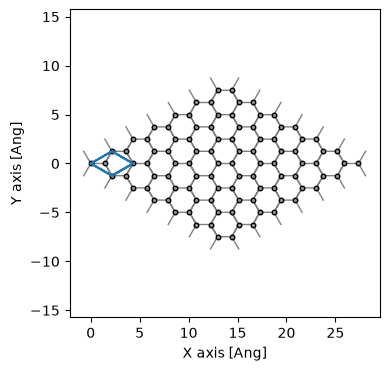

In [4]:
graphene = si.geom.graphene(a_cc)
graphene.plot(axes="xy", nsc=(7, 7, 1), backend="matplotlib")

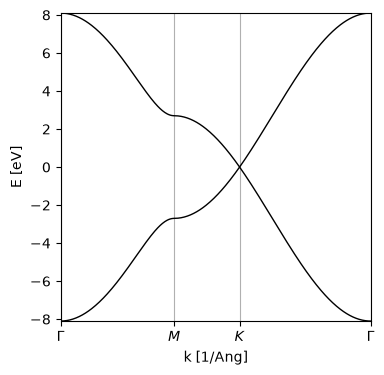

In [5]:
H_gr = tb_hamiltonian(graphene)

band = si.BandStructure(H_gr, [[0, 0, 0], [0, 0.5, 0], [1/3, 2/3, 0], [0, 0, 0]], 400,
                        [r"$\Gamma$", r"$M$", r"$K$", r"$\Gamma$"])
band.plot.bands(Erange=[-12, 12], backend="matplotlib")

## 2. Construct the real-space self-energy

We now create a `RealSpaceSE` object for an $N\times N$ graphene region. The periodic tight-binding Hamiltonian provides the reference environment, while the real-space size determines the finite region on which the embedding self-energy is represented.

The $k$-point sampling used in `setup` controls the Brillouin-zone average and should be converged for quantitative calculations.

The construction of this object is somewhat complicated and has a set of required input options:

1. `parent`: the Hamiltonian
2. `semi_axis`: which axis to use for the recursive calculation of the self-energy
3. `k_axes`: which axes to integrate in the Brillouin zone
4. `unfold`: how many times the object needs to be unfolded along each lattice vector, this is an integer vector of length three

In [6]:
N = 12                       # size of the N x N real-space region
eta = 1e-3                   # broadening [eV] used throughout the tutorial
nk = int(np.ceil(3000 / N))  # k-points along the Brillouin-zone integrated direction

RSSE = si.RealSpaceSE(H_gr,
                      semi_axis=0,       # 1st lattice vector: recursive (semi-infinite) self-energy
                      k_axes=1,          # 2nd lattice vector: Brillouin-zone integral
                      unfold=(N, N, 1),  # the real-space region is N x N unit cells
                      eta=eta)
RSSE.setup(bz=si.MonkhorstPack(H_gr, [1, nk, 1]))

Now we can create the real-space self-energy.
In TBtrans (and TranSiesta) the electrode atomic indices must be in consecutive order. This is a little troublesome since the natural order in a device would be in order according to $x$, $y$ or $z$. To create the correct order we extract the real-space coupling matrix which is where the real-space self-energy would live. The self-energy $\boldsymbol\Sigma^{\mathcal R}(E)$ is calculated using:

$$\boldsymbol\Sigma^{\mathcal R}(E)=(E+i\eta)\mathbf S^{\mathcal R}-\mathbf H^{\mathcal R}- (\boldsymbol G^{\mathcal R}(E))^{-1}$$
 
Where $\mathbf S^{\mathcal R}$ and  $\mathbf H^{\mathcal R}$
are the real-space overlap matrix and Hamiltonian, respectively. Another way to calculate the self-energy would be to transfer the Green function from the infinite bulk $\infty$ into the region of interest $\mathcal R$ :

$$\boldsymbol\Sigma^{\mathcal R}(E)=\mathbf V_{\infty/\mathcal R,\mathcal R}\mathbf G_{\mathcal R,\infty/\mathcal R}\mathbf V_{\mathcal R,\infty/\mathcal R}$$
The self-energy only lives on the boundary that $ \mathcal V_{\mathcal R,\infty/\mathcal R} $ couples to. Exactly this region is extracted using `real_space_coupling` as below. Take some time to draw a simple 2D lattice coupling and confirm the area that the real-space self-energies couple to. HINT: Draw the unit-cell for a 4x4 square lattice with nearest-neighbour couplings, then mark the atoms that couple to atoms outside the unit-cell.

`real_space_coupling(ret_indices=True)` returns the part of the real-space region that couples to the surrounding periodic environment, together with the corresponding atom indices. These are the atoms on which the coupling form of the RSSE acts.

In [7]:
_, rs_atoms = RSSE.real_space_coupling(ret_indices=True)
n_rs = len(rs_atoms)  # number of atoms the RSSE couples to
n_rs

46

Next we construct the finite $N	\times N$ graphene device. For convenience, we reorder its atoms so that the RSSE coupling atoms come **first**, followed by the atoms in the interior. This ordering is not a physical requirement; it simply makes the later matrix operations easier because the RSSE can be inserted directly into the upper-left block of the inverse Green-function matrix.

The `real_space_parent` method returns the Hamiltonian that obeys the unfolded size - in this case $N\times N$ times larger. One may always use this method to get the correct device order of atoms, since the order of tiling is determined by the `semi_axis` and `k_axes` arguments, and it is the order that the indices from `real_space_coupling` refer to.

In [8]:
# The N x N graphene region, with the same atomic order as `rs_atoms`
H_parent = RSSE.real_space_parent()

# Re-order the atoms: RSSE coupling atoms first, then the interior atoms
inner_atoms = np.delete(np.arange(H_parent.na), rs_atoms)
H_sheet = H_parent.sub(np.concatenate([rs_atoms, inner_atoms]))

# Device indices on which the RSSE acts
idx_rsse = np.arange(n_rs)

The following plot shows the reordered indexing. The electrode/coupling atoms appear first, while the remaining atoms form the interior of the finite graphene region. Checking this ordering visually is a useful way to avoid index-mapping errors later.

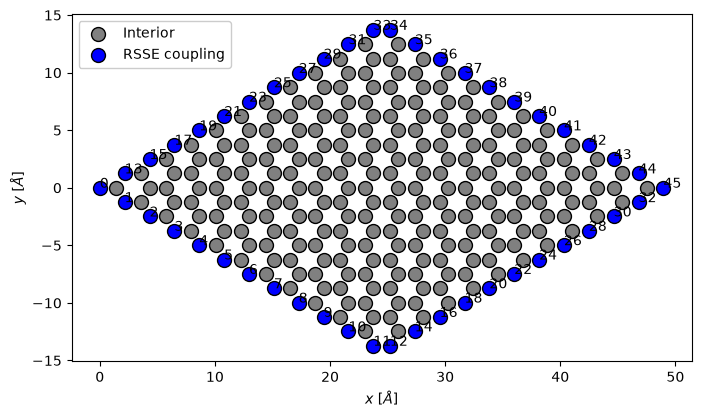

In [9]:
xyz = H_sheet.xyz
fig, ax = plt.subplots(figsize=(8, 8))
plot_atoms(ax, xyz[n_rs:], c="gray", s=100, label="Interior")
plot_atoms(ax, xyz[:n_rs], c="b", s=100, label="RSSE coupling")
for ia in idx_rsse:
    ax.text(*xyz[ia, :2], ia)
ax.legend(loc="upper left");

## 3. DOS and LDOS from the Green function

We now calculate the **density of states (DOS)** and **local density of states (LDOS)** from the retarded Green function of the embedded graphene region. For a non-orthogonal basis, the total DOS is evaluated as:

$$D(E)=-\frac{1}{\pi}\operatorname{Im}\,\mathrm{Tr}\left[\mathbf G^r(E)\mathbf S\right],$$ and the diagonal elements of $\mathbf G^r\mathbf S$ provide an orbital-resolved LDOS. Here each carbon atom has one orbital, so the orbital-resolved LDOS is also atom-resolved.

`coupling=True` returns only the RSSE block acting on the coupling atoms identified above. Because those atoms were reordered to the beginning of the device, this block is simply inserted on the device indices `idx_rsse` (the first `n_rs` atoms).

The two helper functions below are used for all calculations in this tutorial. `green` accepts any number of self-energies, each given as a pair of (device indices, $\boldsymbol\Sigma$).


In [10]:
def green(E, H, S, self_energies):
    """Retarded Green function G = [(E + i eta) S - H - sum Sigma]^-1

    `self_energies` is a list of (indices, Sigma) pairs; each Sigma
    is inserted in the device block given by its indices.
    """
    A = (E + 1j * eta) * S - H
    for idx, SE in self_energies:
        A[np.ix_(idx, idx)] -= SE
    return np.linalg.inv(A)


def ldos(G, S):
    """Orbital (here atom) resolved DOS: -Im diag(G S) / pi"""
    return -np.imag(np.diag(G @ S)) / np.pi


def ldos_with_rsse(H, energies):
    """LDOS[E, atom] of the finite sheet `H`, embedded by the RSSE on its first `n_rs` atoms."""
    Hk, Sk = H.Hk(format="array"), H.Sk(format="array")
    LDOS = np.zeros((len(energies), H.na))
    for iE, E in enumerate(tqdm(energies, desc="LDOS")):
        SE = RSSE.self_energy(E, coupling=True)
        LDOS[iE] = ldos(green(E, Hk, Sk, [(idx_rsse, SE)]), Sk)
    return LDOS

In [11]:
En = np.linspace(-3, 3, 61)  # energy grid [eV], used throughout the tutorial
LDOS_sheet = ldos_with_rsse(H_sheet, En)

# DOS per atom of the interior region
DOS_sheet = LDOS_sheet[:, n_rs:].mean(axis=1)

LDOS:   0%|          | 0/61 [00:00<?, ?it/s]

Finally, we plot the DOS of the interior region. Away from the artificial boundary, the RSSE should make the finite system reproduce the electronic structure of pristine graphene. This provides a useful validation of the embedding before we use the same RSSE in a more complicated device.

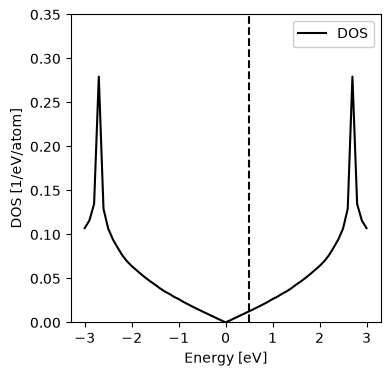

In [12]:
E0 = 0.5  # energy of interest
iE0 = np.abs(En - E0).argmin()

plt.plot(En, DOS_sheet, c="k", label="DOS")
plt.axvline(En[iE0], c="k", ls="--")
plt.xlabel("Energy [eV]")
plt.ylabel("DOS [1/eV/atom]")
plt.ylim(0, 0.35)
plt.legend();

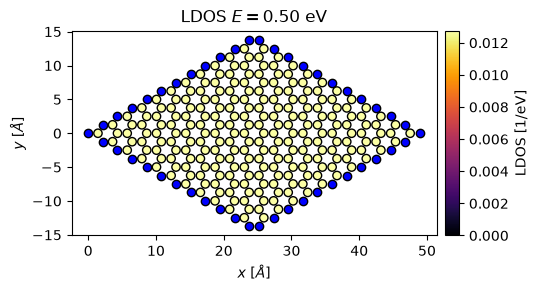

In [13]:
fig, ax = plt.subplots(figsize=(5, 5))
plot_atoms(ax, H_sheet.xyz[:n_rs], c="b")
plot_ldos(ax, H_sheet.xyz[n_rs:], LDOS_sheet[iE0, n_rs:])
ax.set_title(rf"LDOS $E={En[iE0]:.2f}$ eV");

### Visualizing the RSSE
We can plot where the self energy lives in the electrode region. Here the imaginary part of the diagonal of $\boldsymbol\Sigma^{\mathcal R}$ is shown.

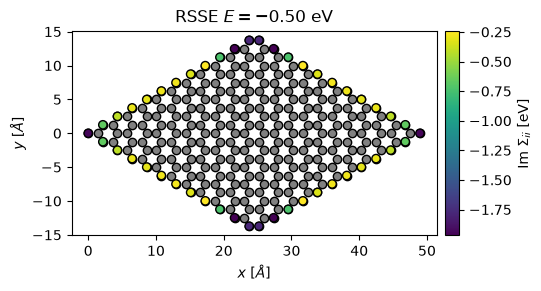

In [14]:
E = -0.5
SE = RSSE.self_energy(E, coupling=True)

fig, ax = plt.subplots(figsize=(5, 5))
plot_atoms(ax, H_sheet.xyz, c="gray")
sc = plot_atoms(ax, H_sheet.xyz[:n_rs], c=SE.diagonal().imag, cmap="viridis")
add_colorbar(ax, sc, r"Im $\Sigma_{ii}$ [eV]")
ax.set_title(rf"RSSE $E={E:.2f}$ eV");

# II. Single vacancy
Now we proceed to remove an atom in the device region. This atomic vacancy gives rise to a localized state

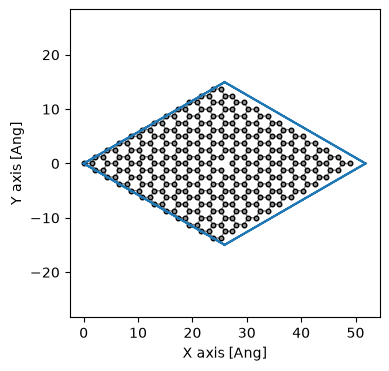

In [15]:
idx_atom = 178  # an interior atom close to the centre of the sheet
H_vac = H_sheet.remove(idx_atom)  # idx_atom >= n_rs, so the RSSE atoms are still the first n_rs atoms
H_vac.geometry.plot(axes="xy", backend="matplotlib")

In [16]:
LDOS_vac = ldos_with_rsse(H_vac, En)
DOS_vac = LDOS_vac[:, n_rs:].mean(axis=1)

LDOS:   0%|          | 0/61 [00:00<?, ?it/s]

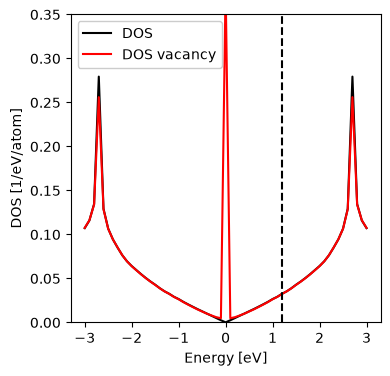

In [17]:
E0 = 1.2  # energy of interest
iE0 = np.abs(En - E0).argmin()

plt.plot(En, DOS_sheet, c="k", label="DOS")
plt.plot(En, DOS_vac, c="r", label="DOS vacancy")
plt.axvline(En[iE0], c="k", ls="--")
plt.xlabel("Energy [eV]")
plt.ylabel("DOS [1/eV/atom]")
plt.ylim(0, 0.35)
plt.legend();

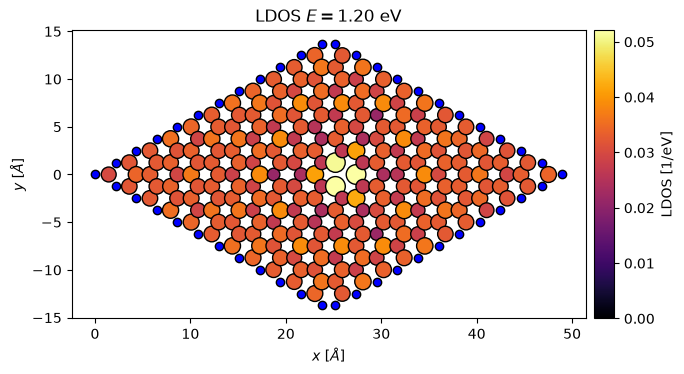

In [18]:
ldos_E0 = LDOS_vac[iE0, n_rs:]

fig, ax = plt.subplots(figsize=(7, 7))
plot_atoms(ax, H_vac.xyz[:n_rs], c="b")
plot_ldos(ax, H_vac.xyz[n_rs:], ldos_E0, s=200 * ldos_E0 / ldos_E0.max())
ax.set_title(rf"LDOS $E={En[iE0]:.2f}$ eV");

# III. Injection from a wire

We model an Au "STM" wire in contact with a carbon atom in pristine graphene. Five explicit Au atoms are included along $z$, and the semi-infinite continuation is represented by a recursive electrode self-energy.

### 1. Construct STM Hamiltonian

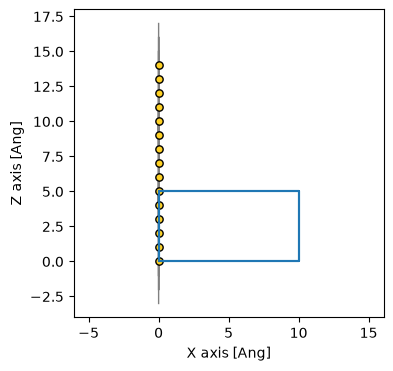

In [19]:
wire = si.Geometry([0, 0, 0], atoms=si.Atom("Au", R=1.0001),
                   lattice=si.Lattice([10, 10, 1], nsc=[1, 1, 3])).tile(5, 2)
H_wire = si.Hamiltonian(wire)
H_wire.construct([(0.1, 1.1), (0, -0.75)])
H_wire.geometry.plot(axes="xz", nsc=[1, 1, 3], backend="matplotlib")

We plot the band structure of the wire to show that it is a metallic system.

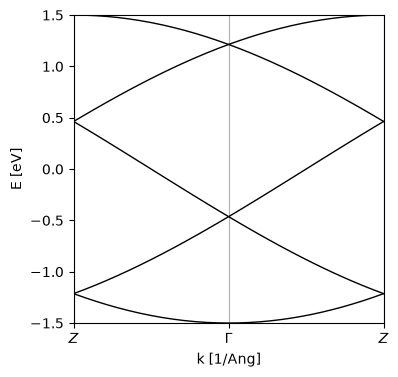

In [20]:
band = si.BandStructure(H_wire, [[0, 0, 0.5], [0, 0, 0], [0, 0, 0.5]], 30,
                        [r"$Z$", r"$\Gamma$", r"$Z$"])
band.plot.bands(Erange=[-12, 12], backend="matplotlib")

### 2. Contact the STM to graphene

We contact the first Au atom of the wire with a carbon atom in graphene. The hopping is set explicitly in both directions to keep the device Hamiltonian Hermitian.

In [21]:
# Place the wire 2 Ang above the graphene atom `idx_atom`
H_gr_stm = H_sheet.add(H_wire, offset=H_sheet.xyz[idx_atom] - H_wire.xyz[0] + [0, 0, 2])

idx_wire = np.flatnonzero(H_gr_stm.atoms.Z == 79)  # Au atoms (appended after graphene)
idx_au = idx_wire[0]                               # the Au atom contacting graphene
H_gr_stm[idx_atom, idx_au] = -1
H_gr_stm[idx_au, idx_atom] = -1

# Remove periodic image hoppings from the finite device; the +C SE supplies the wire continuation.
H_gr_stm.set_nsc([1, 1, 1])

/home/nicpa/.claude/jobs/b9e2a2a8/tmp/venv020/lib/python3.11/site-packages/sisl/viz/processors/xarray.py:208: FutureWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'sc_atom'} to avoid an error in the future.
  new[var] = new[var] * scale


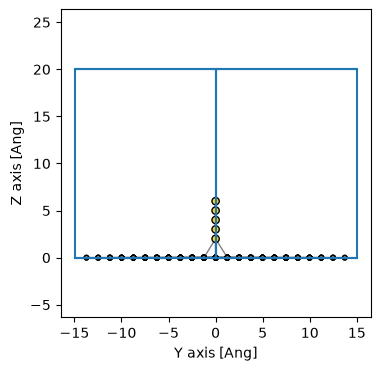

In [22]:
H_gr_stm.geometry.plot(axes="yz", backend="matplotlib")

/home/nicpa/.claude/jobs/b9e2a2a8/tmp/venv020/lib/python3.11/site-packages/sisl/viz/processors/xarray.py:208: FutureWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'sc_atom'} to avoid an error in the future.
  new[var] = new[var] * scale


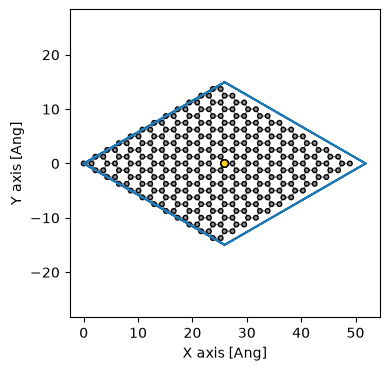

In [23]:
H_gr_stm.geometry.plot(axes="xy", backend="matplotlib")

### 3. Calculate the Transmission

The `+C` recursive self-energy represents the continuation of the wire beyond its last explicit Au atom. It acts on the wire block; the coupling to graphene is already included in the device Hamiltonian.

In [24]:
SE_wire = si.RecursiveSI(H_wire, "+C", eta=1e-5)

We calculate the transmission from the Au wire to graphene  over a chosen energy range. For each energy we:

1. evaluate the bottom and top coupling self-energies, one with rsse electrode the second with semi-infinite electrode
2. insert them into the corresponding blocks of the full device matrix,
3. invert the open-system matrix to obtain $\mathbf G^r$,
4. construct the broadening matrices $\boldsymbol\Gamma=i(\boldsymbol\Sigma-\boldsymbol\Sigma^\dagger)$ for bottom ($B$) and top ($T$) with `se2broadening`, and
5.  evaluate
$$T(E)=\mathrm{Tr}\left[\boldsymbol\Gamma_B\mathbf G^r\boldsymbol\Gamma_T\mathbf G^a\right].$$

Since $\boldsymbol\Gamma_B$ and $\boldsymbol\Gamma_T$ are only non-zero on their electrode atoms, only the block $\mathbf G^r_{BT}$ of the Green function is needed: $T(E)=\mathrm{Tr}[\boldsymbol\Gamma_B\mathbf G^r_{BT}\boldsymbol\Gamma_T(\mathbf G^r_{BT})^\dagger]$.

The same Green function gives the DOS projected onto graphene and the five explicit Au atoms. (This example uses pristine graphene, not the vacancy Hamiltonian.)


In [25]:
def transmission(G, idx_B, Gamma_B, idx_T, Gamma_T):
    """T = Tr[Gamma_B G_BT Gamma_T G_BT^dagger], using only the electrode block G_BT."""
    G_BT = G[np.ix_(idx_B, idx_T)]
    return np.trace(Gamma_B @ G_BT @ Gamma_T @ G_BT.conj().T).real


Hk, Sk = H_gr_stm.Hk(format="array"), H_gr_stm.Sk(format="array")
T_stm = np.zeros(len(En))
LDOS_stm = np.zeros((len(En), H_gr_stm.na))
for iE, E in enumerate(tqdm(En, desc="T")):
    SE_B = RSSE.self_energy(E, coupling=True)  # graphene environment
    SE_T = SE_wire.self_energy(E)              # semi-infinite Au wire
    G = green(E, Hk, Sk, [(idx_rsse, SE_B), (idx_wire, SE_T)])

    T_stm[iE] = transmission(G, idx_rsse, RSSE.se2broadening(SE_B),
                             idx_wire, SE_wire.se2broadening(SE_T))
    LDOS_stm[iE] = ldos(G, Sk)

T:   0%|          | 0/61 [00:00<?, ?it/s]

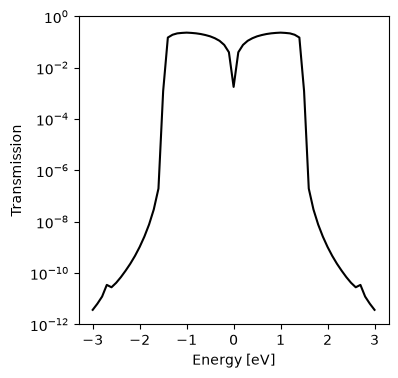

In [26]:
plt.semilogy(En, T_stm, c="k")
plt.xlabel("Energy [eV]")
plt.ylabel("Transmission")
plt.ylim(1e-12, 1);

### 4. Plot the DOS

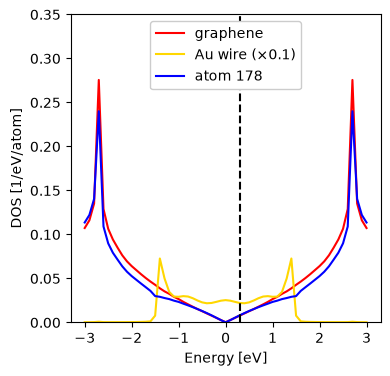

In [27]:
idx_graphene = np.flatnonzero(H_gr_stm.atoms.Z == 6)

E0 = 0.3  # energy of interest
iE0 = np.abs(En - E0).argmin()

plt.plot(En, LDOS_stm[:, idx_graphene].mean(axis=1), c="r", label="graphene")
plt.plot(En, 0.1 * LDOS_stm[:, idx_wire].mean(axis=1), c="gold", label="Au wire (×0.1)")
plt.plot(En, LDOS_stm[:, idx_atom], c="b", label=f"atom {idx_atom}")
plt.axvline(En[iE0], c="k", ls="--")
plt.xlabel("Energy [eV]")
plt.ylabel("DOS [1/eV/atom]")
plt.ylim(0, 0.35)
plt.legend();

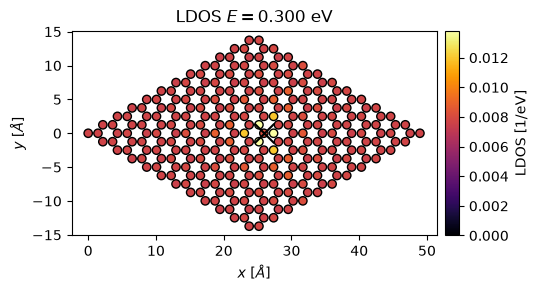

In [28]:
xyz = H_gr_stm.xyz
fig, ax = plt.subplots(figsize=(5, 5))
plot_ldos(ax, xyz[idx_graphene], LDOS_stm[iE0, idx_graphene])
plot_atoms(ax, xyz[[idx_atom]], c="k", marker="x", s=200)
ax.set_title(rf"LDOS $E={En[iE0]:.3f}$ eV");

### 5. STM-injected spectral bond currents

At a selected energy $E_0$, the **spectral weight** from the STM contact is

$$\mathbf A_T(E_0)=\mathbf G^r(E_0)\boldsymbol\Gamma_T(E_0)\mathbf G^a(E_0), \qquad \boldsymbol\Gamma_T=i(\boldsymbol\Sigma_T-\boldsymbol\Sigma_T^\dagger).$$

The energy-resolved particle flow from orbital $i$ to $j$ (positive for $i\to j$) is

$$j_{i\to j}^{(T)}(E_0)=-2\,\mathrm{Im}\!\left[\big(H_{ij}-E_0S_{ij}\big)(A_T)_{ji}\right].$$

Here each atom has one orthogonal orbital, so $S_{ij}=0$ for distinct atoms. **Only nonzero Hamiltonian bonds carry a bond current.** We therefore take the bonds directly from the non-zero elements of $\mathbf H-E_0\mathbf S$ (no distance cut-off is needed). The arrow direction indicates the sign; its color indicates $|j|$. The result is an energy-resolved *STM-injected* contribution, not a finite-bias current by itself. A two-terminal charge current requires the occupation difference, with $I=(e/h)\int dE\,[f_T(E)-f_B(E)]\,T(E)$ per spin (up to the chosen sign convention).

In [29]:
def spectral_function(G, idx, Gamma):
    """A = G Gamma G^dagger for a broadening matrix Gamma living on the device indices `idx`."""
    G_i = G[:, idx]
    return G_i @ Gamma @ G_i.conj().T


def bond_currents(H, S, A, E):
    """Spectral bond currents j_{i->j} = -2 Im[(H_ij - E S_ij) A_ji] for all coupled atoms i < j."""
    M = H - E * S
    i, j = np.nonzero(np.triu(M, k=1))
    return i, j, -2 * np.imag(M[i, j] * A[j, i])

In [30]:
E0 = 0.3  # energy of interest
SE_B = RSSE.self_energy(E0, coupling=True)
SE_T = SE_wire.self_energy(E0)
G = green(E0, Hk, Sk, [(idx_rsse, SE_B), (idx_wire, SE_T)])
Gamma_B = RSSE.se2broadening(SE_B)
Gamma_T = SE_wire.se2broadening(SE_T)

# Spectral bond currents injected from the STM wire
A_T = spectral_function(G, idx_wire, Gamma_T)
i, j, J = bond_currents(Hk, Sk, A_T, E0)

# Check the graphene--first-Au bond flux against the total transmission.
tip_bond = (i == idx_atom) & (j == idx_au)
T_E0 = transmission(G, idx_rsse, Gamma_B, idx_wire, Gamma_T)
print(f"Au -> graphene bond flux: {-J[tip_bond].sum():.5g}; T(E0): {T_E0:.5g}")

Au -> graphene bond flux: 0.1141; T(E0): 0.11306


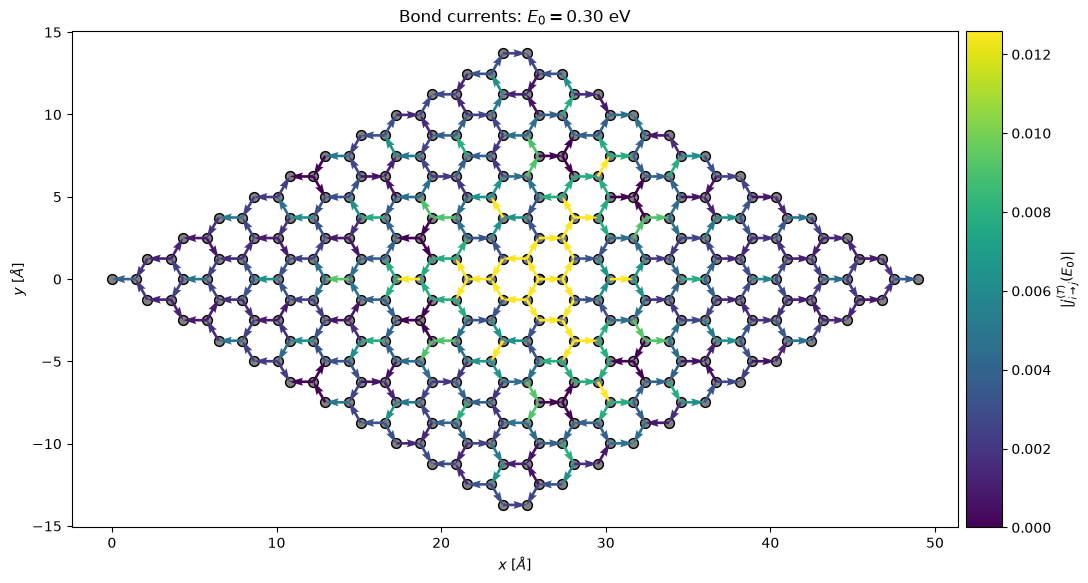

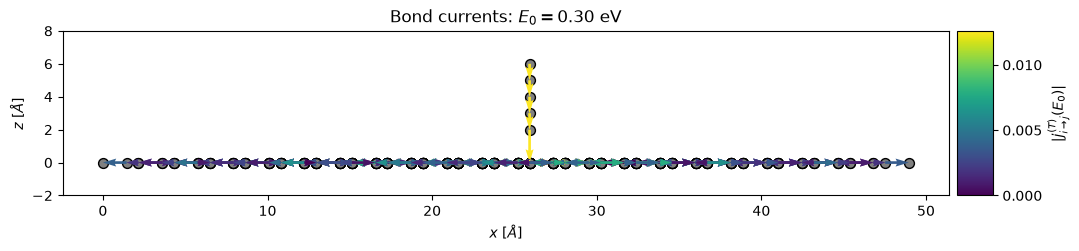

In [31]:
vmax = 0.1 * np.abs(J).max()  # saturate the strongest bonds to reveal weaker currents
for axes, figsize in [("xy", (12, 7)), ("xz", (12, 5))]:
    fig, ax = plt.subplots(figsize=figsize)
    plot_atoms(ax, xyz, axes, s=50, c="gray", zorder=0)
    q = plot_bond_currents(ax, xyz, i, j, J, axes, vmax=vmax)
    add_colorbar(ax, q, r"$|j_{i\to j}^{(T)}(E_0)|$")
    ax.set_title(rf"Bond currents: $E_0={E0:.2f}$ eV")
    if axes == "xz":
        ax.set_ylim(-2, 8)

### 5. Exercise: Now study the STM contacted to a carbon close to a vacancy


# IV. Vertical transport through a carbon nanotube

## 1. CNT band structure


In [32]:
cnt = si.Geometry.read("CNT/cnt_prist.xyz")
cnt.plot(axes="xz")

warn:0: SislWarning: Geometry.close_sc has been passed an 'atoms' argument together with an R value larger than the orbital ranges. If used together with 'sparse-matrix.construct' this can result in wrong couplings.


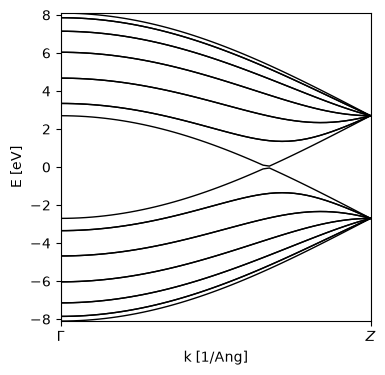

In [33]:
H_cnt = tb_hamiltonian(cnt)
band = si.BandStructure(H_cnt, [[0, 0, 0], [0, 0, 1/2]], 50, [r"$\Gamma$", r"$Z$"])
band.plot.bands(Erange=[-9, 9], backend="matplotlib")

We employ a Monkhorst-Pack grid to calculate the k-averaged DOS, using a Gaussian distribution to smear the DOS.

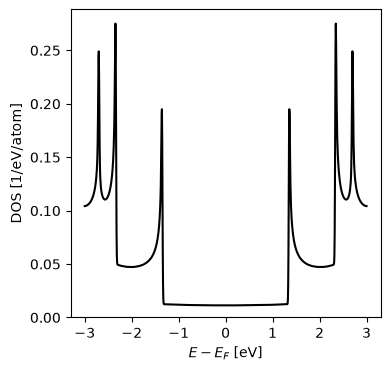

In [34]:
bz = si.MonkhorstPack(H_cnt, [1, 1, 1000])
E_cnt = np.linspace(-3, 3, 1001)
dist = si.get_distribution("gaussian", smearing=0.01)
DOS_cnt = bz.apply.average.eigenstate(wrap=lambda es: es.DOS(E_cnt, distribution=dist)) / H_cnt.na

plt.plot(E_cnt, DOS_cnt, c="k")
plt.xlabel("$E - E_F$ [eV]")
plt.ylabel("DOS [1/eV/atom]")
plt.ylim(0, None);

## 2. Construct the device Hamiltonian

We now read the graphene–CNT–graphene structure written to the FDF file and construct its tight-binding Hamiltonian.

The atom ordering is important and was chosen deliberately as

**bottom graphene $\rightarrow$ CNT $\rightarrow$ top graphene**.

Within each graphene block, the RSSE coupling atoms remain first. This lets us reuse the coupling self-energy calculated in Section I without an additional coordinate remapping.
We have created carbon nanotubes of **6** and **12** repetitions for you.

In [35]:
n = 6  # number of CNT repetitions: 6 or 12
device = si.Geometry.read(f"CNT/CNT{n}_device.fdf")

# The separate geometries are only used to know the size of each block
n_bottom = si.Geometry.read("CNT/gr_bot.xyz").na
n_cnt = si.Geometry.read(f"CNT/cnt_{n}.xyz").na

device.plot(axes="xz", show_cell=False)

In [36]:
H_dev = tb_hamiltonian(device)
H_dev.set_nsc([1, 1, 1])

warn:0: SislWarning: Geometry.close_sc has been passed an 'atoms' argument together with an R value larger than the orbital ranges. If used together with 'sparse-matrix.construct' this can result in wrong couplings.


## 3. Transport with RSSE for bottom and top graphene

The bottom and top electrodes are identical pristine graphene environments, so the same RSSE construction can be used for both sides. We therefore calculate the self-energy once per energy and insert it on both the bottom and the top coupling atoms.

Because the device ordering is **bottom graphene $\rightarrow$ CNT $\rightarrow$ top graphene**.
the global indices of the two RSSE coupling regions follow directly from the sizes of these three blocks.


In [37]:
# Bottom graphene starts at 0, top graphene starts after bottom + CNT
idx_bottom = np.arange(n_rs)
idx_top = n_bottom + n_cnt + np.arange(n_rs)

# Sanity check: both sheets start with the RSSE coupling atoms, in the same (x, y) order as H_sheet
for idx in (idx_bottom, idx_top):
    assert np.allclose(device.xyz[idx, :2], H_sheet.xyz[:n_rs, :2])

idx_inner = np.setdiff1d(np.arange(H_dev.na), np.concatenate([idx_bottom, idx_top]))

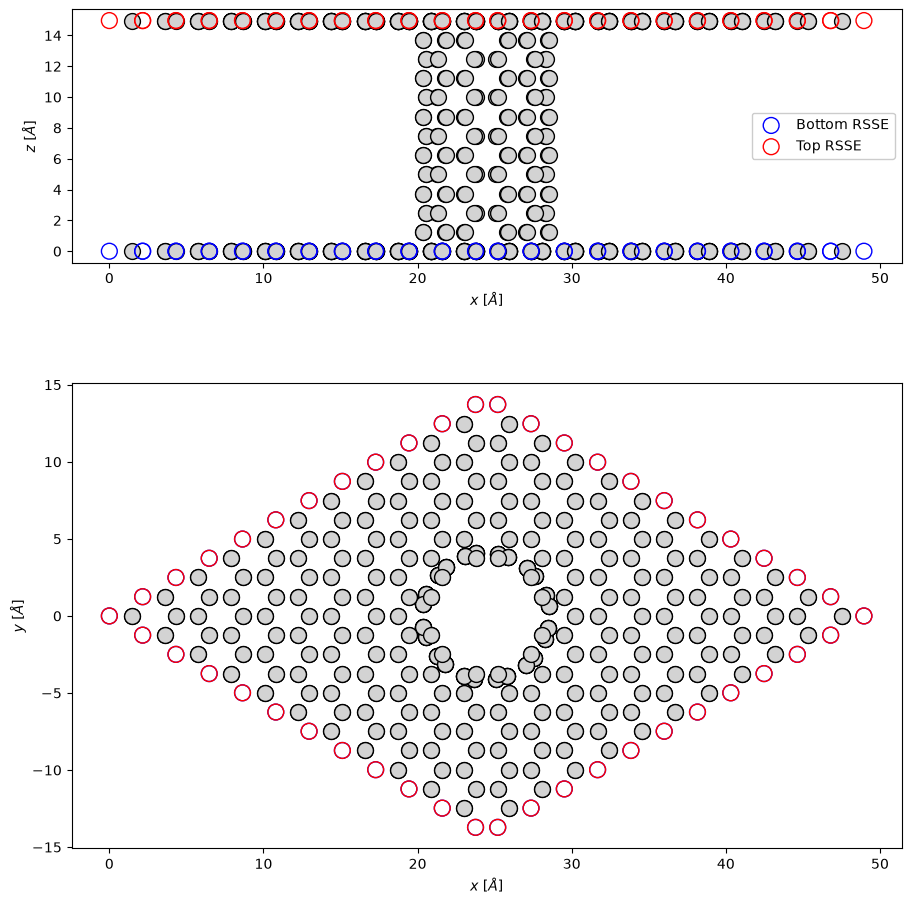

In [38]:
xyz = device.xyz
fig, axs = plt.subplots(2, 1, figsize=(9, 10), layout="constrained")
for ax, axes in zip(axs, ["xz", "xy"]):
    plot_atoms(ax, xyz[idx_inner], axes, c="lightgray", s=130, zorder=0)
    plot_atoms(ax, xyz[idx_bottom], axes, facecolors="none", edgecolors="b", s=130, label="Bottom RSSE")
    plot_atoms(ax, xyz[idx_top], axes, facecolors="none", edgecolors="r", s=130, label="Top RSSE")
axs[0].legend();

We calculate the transmission from the bottom graphene sheet to the top graphene sheet over a chosen energy range. For each energy we:

1. evaluate the bottom and top coupling self-energies,
2. insert them into the corresponding blocks of the full device matrix,
3. invert the open-system matrix to obtain $\mathbf G^r$,
4. construct the broadening matrices $\boldsymbol\Gamma_B=\boldsymbol\Gamma_T$, and
5.  evaluate
$$T(E)=\mathrm{Tr}\left[\boldsymbol\Gamma_B\mathbf G^r\boldsymbol\Gamma_T\mathbf G^a\right].$$

The same Green function is also used to calculate the total DOS and its projections onto the bottom graphene, CNT, and top graphene regions.

In [39]:
Hk, Sk = H_dev.Hk(format="array"), H_dev.Sk(format="array")
T_dev = np.zeros(len(En))
LDOS_dev = np.zeros((len(En), H_dev.na))
for iE, E in enumerate(tqdm(En, desc="T")):
    SE = RSSE.self_energy(E, coupling=True)  # same RSSE for bottom and top graphene
    G = green(E, Hk, Sk, [(idx_bottom, SE), (idx_top, SE)])
    Gamma = RSSE.se2broadening(SE)

    T_dev[iE] = transmission(G, idx_bottom, Gamma, idx_top, Gamma)
    LDOS_dev[iE] = ldos(G, Sk)

T:   0%|          | 0/61 [00:00<?, ?it/s]

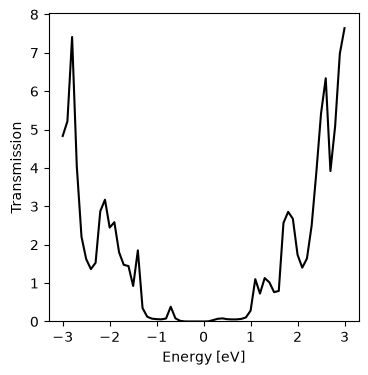

In [40]:
plt.plot(En, T_dev, c="k")
plt.xlabel("Energy [eV]")
plt.ylabel("Transmission")
plt.ylim(0, None);

## 4. Visualize the DOS and LDOS

The DOS projections show which part of the device contributes states at a given energy. The LDOS maps provide the complementary real-space picture: they show where those states are localized within the graphene–CNT–graphene structure.


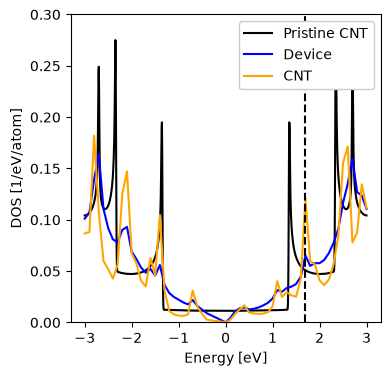

In [41]:
idx_cnt = np.arange(n_bottom, n_bottom + n_cnt)

E0 = 1.75  # energy of interest
iE0 = np.abs(En - E0).argmin()

plt.plot(E_cnt, DOS_cnt, c="k", label="Pristine CNT")
plt.plot(En, LDOS_dev.mean(axis=1), c="b", label="Device")
plt.plot(En, LDOS_dev[:, idx_cnt].mean(axis=1), c="orange", label="CNT")
plt.axvline(En[iE0], c="k", ls="--")
plt.xlabel("Energy [eV]")
plt.ylabel("DOS [1/eV/atom]")
plt.ylim(0, 0.3)
plt.legend(loc=1);

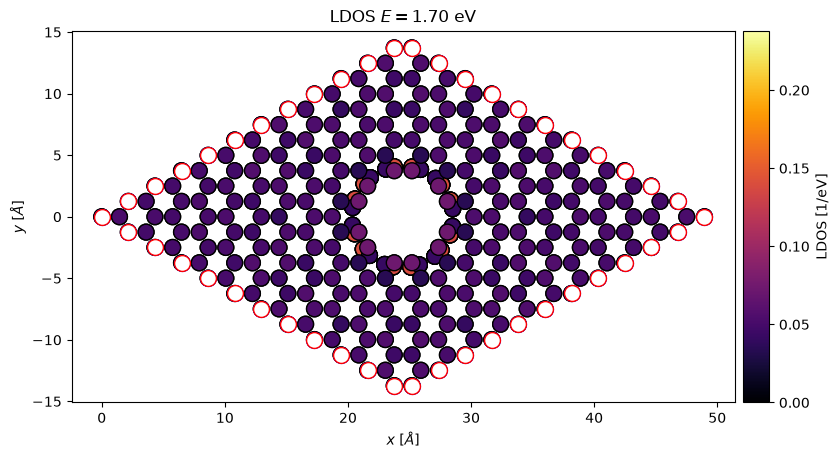

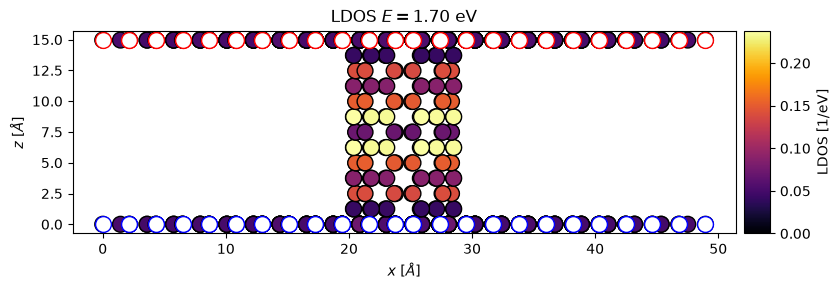

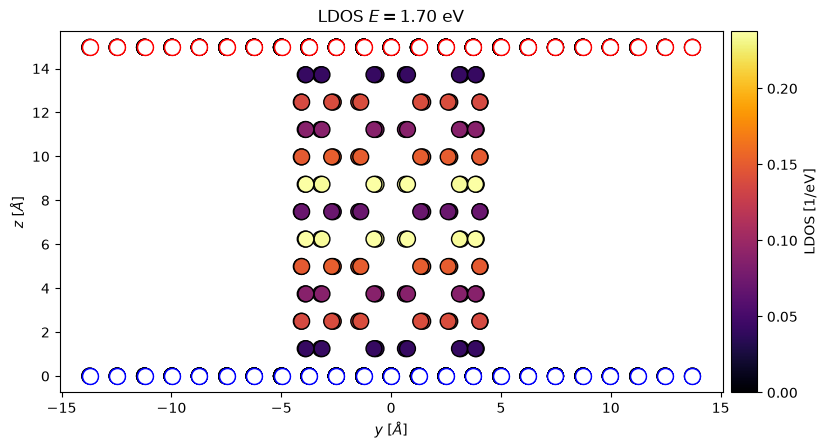

In [42]:
for axes in ["xy", "xz", "yz"]:
    fig, ax = plt.subplots(figsize=(9, 9))
    plot_ldos(ax, xyz, LDOS_dev[iE0], axes, s=130)
    plot_atoms(ax, xyz[idx_bottom], axes, c="white", edgecolors="b", s=130, label="Bottom RSSE")
    plot_atoms(ax, xyz[idx_top], axes, c="white", edgecolors="r", s=130, label="Top RSSE")
    ax.set_title(rf"LDOS $E={En[iE0]:.2f}$ eV")

### CNT bond currents: source-resolved flow from bottom graphene

For the two graphene electrodes, we inject from the **bottom** one:

$$\mathbf A_B(E_0)=\mathbf G^r(E_0)\boldsymbol\Gamma_B(E_0)\mathbf G^a(E_0),$$

$$j_{i\to j}^{(B)}(E_0)=-2\,\mathrm{Im}\!\left[\big(H_{ij}-E_0S_{ij}\big)(A_B)_{ji}\right].$$

The arrows show where states incoming from bottom graphene propagate through the CNT and into the top electrode. Negative values reverse arrow directions. In a two-terminal device, the **signed sum** of these bond currents across a complete bottom-to-top cut should approach the transmission $T(E_0)$ (per spin). This is a useful check of indexing, signs, and Hamiltonian connectivity. Finite $\eta$ acts as additional weak absorption, so exact current conservation requires the $\eta\to0^+$ limit and consistent electrode broadenings. The plotted $j^{(B)}$ is not an equilibrium net current.

In [43]:
E0 = 1.75  # energy of interest
SE = RSSE.self_energy(E0, coupling=True)
G = green(E0, Hk, Sk, [(idx_bottom, SE), (idx_top, SE)])
Gamma = RSSE.se2broadening(SE)

# Spectral bond currents injected from bottom graphene
A_B = spectral_function(G, idx_bottom, Gamma)
i, j, J = bond_currents(Hk, Sk, A_B, E0)

# Signed bottom-graphene -> rest-of-device flux versus T(E0).
cut = (i < n_bottom) & (j >= n_bottom)
T_E0 = transmission(G, idx_bottom, Gamma, idx_top, Gamma)
print(f"Bottom-graphene cut flux: {J[cut].sum():.5g}; T(E0): {T_E0:.5g}")

# Only draw the non-negligible currents
keep = np.abs(J) > 1e-5 * np.abs(J).max()
i, j, J = i[keep], j[keep], J[keep]

Bottom-graphene cut flux: 2.6971; T(E0): 2.6255


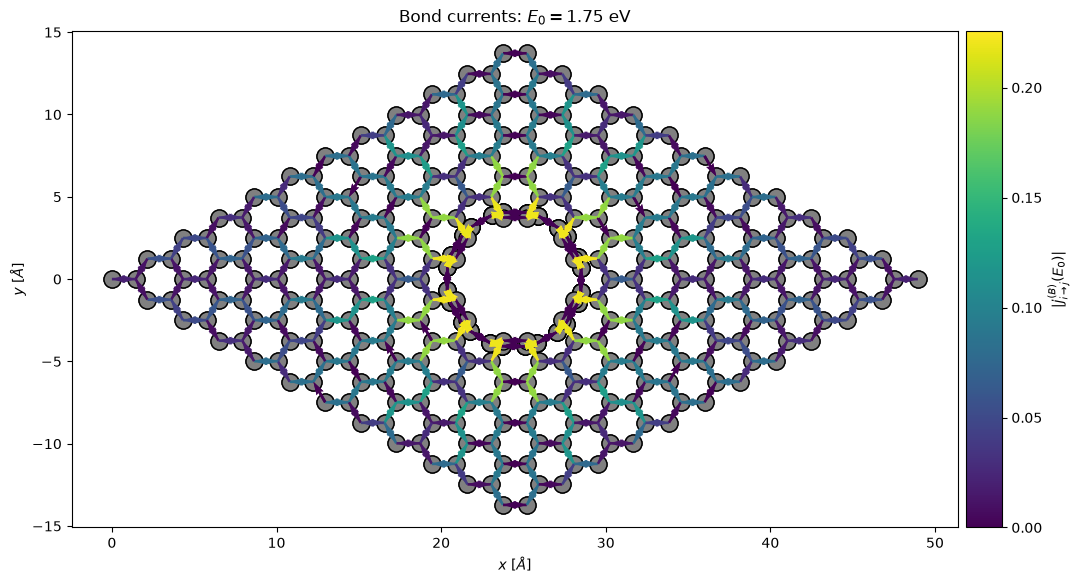

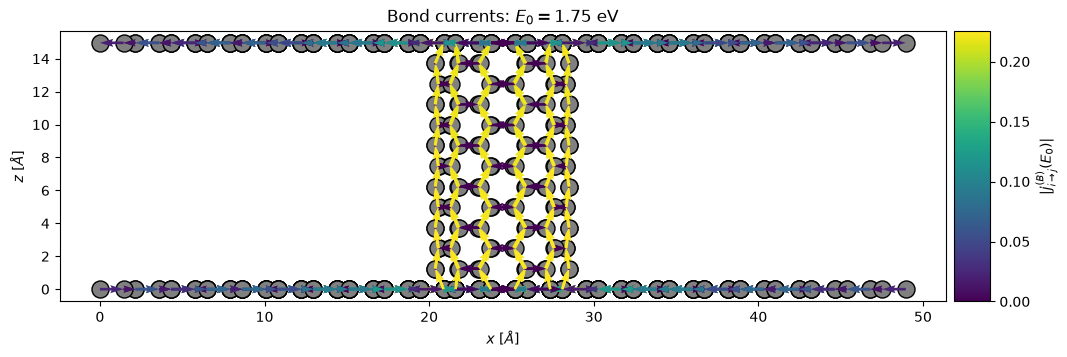

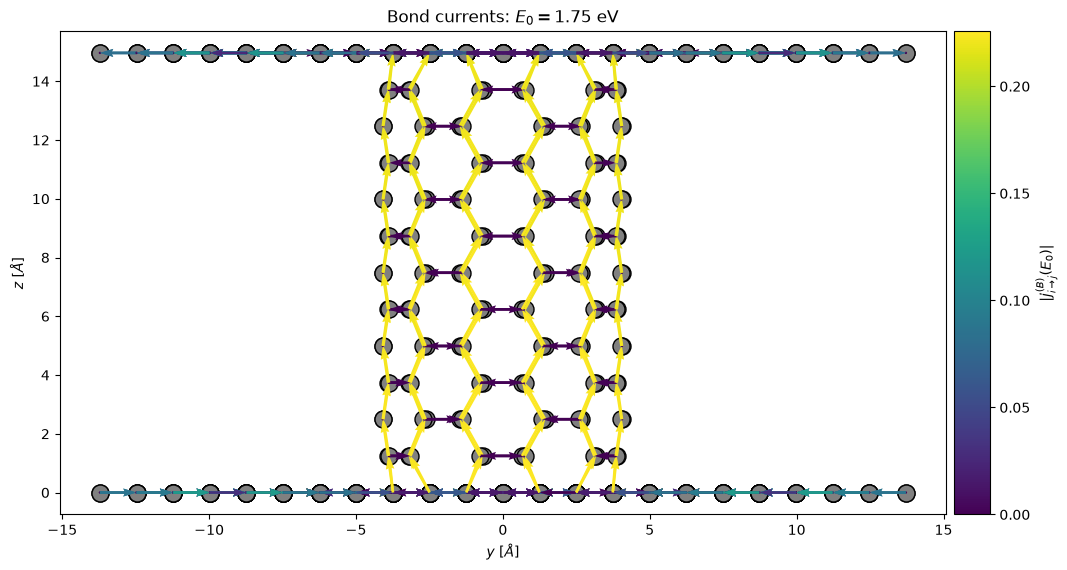

In [44]:
for axes in ["xy", "xz", "yz"]:
    fig, ax = plt.subplots(figsize=(12, 7))
    plot_atoms(ax, xyz, axes, s=150, c="gray", zorder=0)
    q = plot_bond_currents(ax, xyz, i, j, J, axes, vmax=np.abs(J).max())
    add_colorbar(ax, q, r"$|j_{i\to j}^{(B)}(E_0)|$")
    ax.set_title(rf"Bond currents: $E_0={E0:.2f}$ eV")